# Deep Learning Project: Recommendation Scoring Model
## Problem Definition
Users cannot rate every available movie, making it difficult to identify which movies they might enjoy.

## Proposed Solution
Build a Deep Learning Recommendation Scoring Model using the MovieLens dataset. An Artificial Neural Network (ANN) learns from users' previous rating patterns to predict how a user might rate an unseen movie, supporting personalized movie recommendations.

Dataset Source: MovieLens, as recommended in the project file **(https://grouplens.org/datasets/movielens/)**

In [ ]:
#import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from tensorflow import keras


I0000 00:00:1795011983.755167     171 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795011995.779121     171 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1795012009.139393     171 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


- Data loading and exploring

In [ ]:
ratings = pd.read_csv("/content/ratings.csv")
movies = pd.read_csv("/content/movies.csv")

In [ ]:
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [ ]:
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [ ]:
print("ratings shape:", ratings.shape)
print("movies shape:", movies.shape)

ratings shape: (100836, 4)
movies shape: (9742, 3)


In [ ]:
ratings.info()

<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB


In [ ]:
ratings.describe()

,userId,movieId,rating,timestamp
count,100836.000000,100836.000000,100836.000000,1.008360e+05
mean,326.127564,19435.295718,3.501557,1.205946e+09
std,182.618491,35530.987199,1.042529,2.162610e+08
min,1.000000,1.000000,0.500000,8.281246e+08
25%,177.000000,1199.000000,3.000000,1.019124e+09
50%,325.000000,2991.000000,3.500000,1.186087e+09
75%,477.000000,8122.000000,4.000000,1.435994e+09
max,610.000000,193609.000000,5.000000,1.537799e+09


In [ ]:
ratings.isnull().sum()

userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

In [ ]:
ratings.duplicated().sum()

np.int64(0)

- EDA

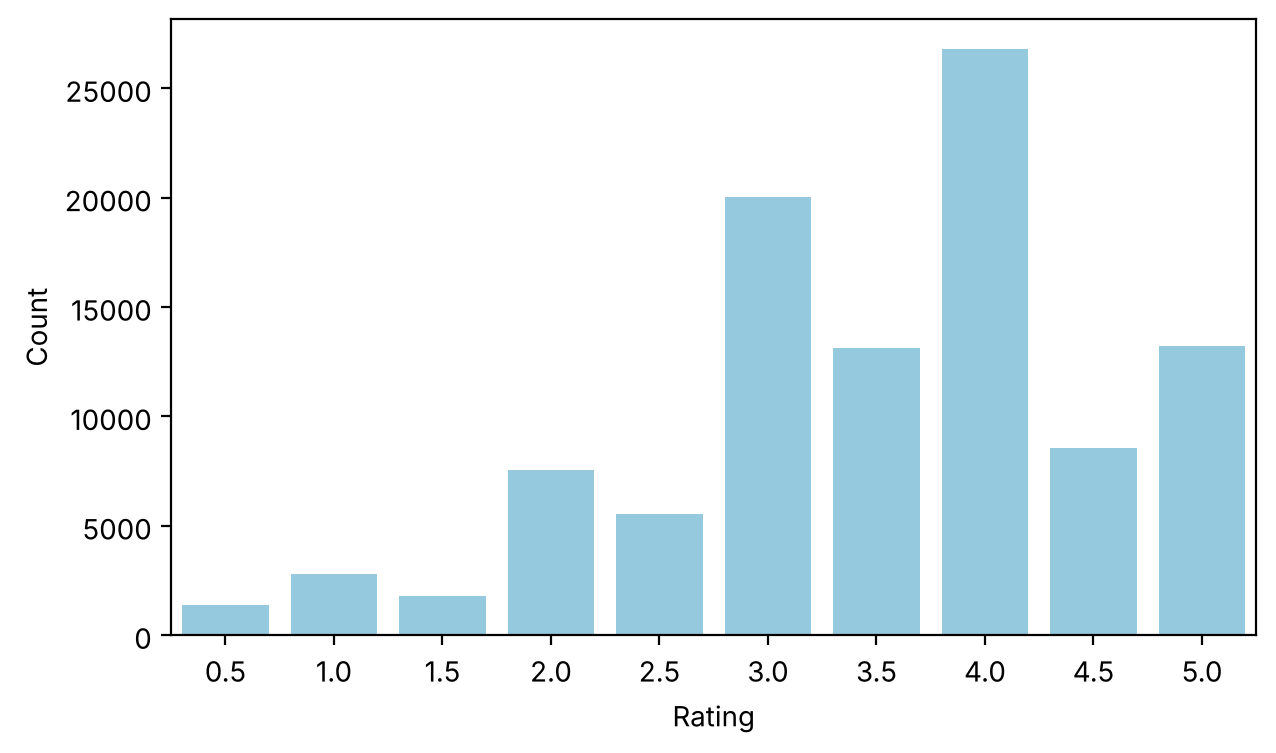

In [ ]:
#ratings distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=ratings, x="rating", color="skyblue")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

most movie ratings are between 3.0 and 5.0, with 4.0 being the most frequent rating

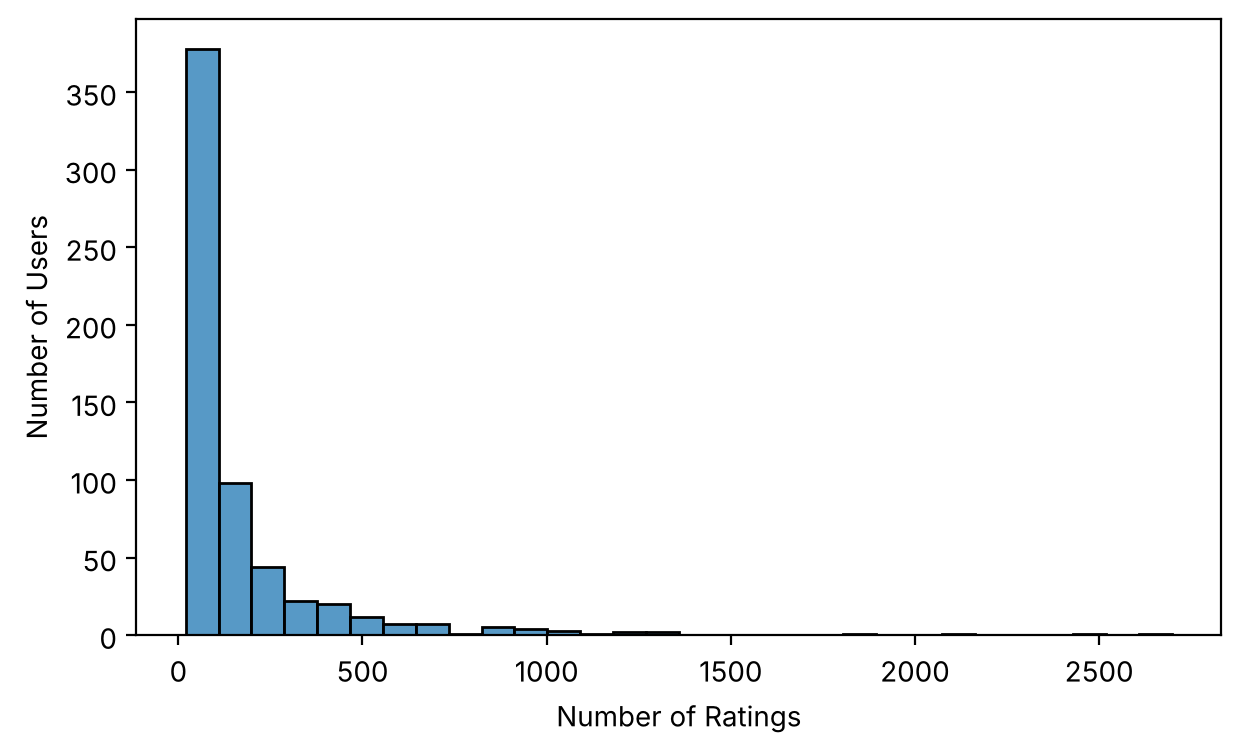

In [ ]:
# Ratings per user
ratings_per_user = ratings.groupby("userId").size()

plt.figure(figsize=(7, 4))
sns.histplot(ratings_per_user, bins=30)
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")
plt.show()

Most users have few ratings while a small number of users have rated thousands of movies

 Feature selection & Encoding

In [ ]:
df = ratings[["userId", "movieId", "rating"]].copy()
df.head()

,userId,movieId,rating
0,1,1,4.0
1,1,3,4.0
2,1,6,4.0
3,1,47,5.0
4,1,50,5.0


In [ ]:
u_encoder = LabelEncoder()
m_encoder = LabelEncoder()
df["user_encoded"] = u_encoder.fit_transform(df["userId"])
df["movie_encoded"] = m_encoder.fit_transform(df["movieId"])

df.head()

,userId,movieId,rating,user_encoded,movie_encoded
0,1,1,4.0,0,0
1,1,3,4.0,0,2
2,1,6,4.0,0,5
3,1,47,5.0,0,43
4,1,50,5.0,0,46


In [ ]:
train_df, temp_df = train_test_split(
    df, test_size=0.2, random_state=42
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=42
)

In [ ]:
train_users = set(train_df["userId"])
train_movies = set(train_df["movieId"])
val_df = val_df[val_df["userId"].isin(train_users) & val_df["movieId"].isin(train_movies)].copy()
test_df = test_df[test_df["userId"].isin(train_users) &test_df["movieId"].isin(train_movies)].copy()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (80668, 5)
Validation: (9660, 5)
Test: (9695, 5)


In [ ]:
#save data
train_df.to_csv("movieLens_train.csv", index=False)
val_df.to_csv("movieLens_validation.csv", index=False)
test_df.to_csv("movieLens_test.csv", index=False)

In [ ]:
#select features and target column
n_users = df["user_encoded"].nunique()
n_movies = df["movie_encoded"].nunique()

# shift movie numbers after the user numbers, so each user and each movie gets its own embedding
def get_features(data):
    X = data[["user_encoded", "movie_encoded"]].copy()
    X["movie_encoded"] = X["movie_encoded"] + n_users
    return X

X_train = get_features(train_df)
y_train = train_df["rating"]

X_val = get_features(val_df)
y_val = val_df["rating"]

X_test = get_features(test_df)
y_test = test_df["rating"]

# Model design and Training

### Baseline Model

In [ ]:
Baseline_Model = keras.Sequential([
    keras.Input(shape=(2,)),
    keras.layers.Embedding(n_users + n_movies, 32),  # learns a vector for each user and each movie
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(1, activation='linear') #linear because we expect a numerical rating



])

Baseline_Model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 2, 32)          │       330,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 349,377 (1.33 MB)

 Trainable params: 349,377 (1.33 MB)

 Non-trainable params: 0 (0.00 B)

**Model Architecture:**

* Embedding Layer: turns each user and movie ID into a vector of 32 learned numbers, so the model can learn user taste and movie similarity.
* Hidden Layers: 3 layers.
* Activation Function: ReLU for all hidden layers.
* Output Layer: 1 neuron because we predict one movie rating.
* Output Activation: Linear.

### Compile and Train the Baseline Model

In [ ]:
Baseline_Model.compile(
    optimizer= keras.optimizers.Adam(learning_rate= 0.0001),
    loss='mse',
    metrics=['mae']
)

# Train the baseline model and store history
baseline_history = Baseline_Model.fit(X_train, y_train, epochs=20, batch_size=32, validation_data=(X_val, y_val))


Epoch 1/20


   1/2521 ━━━━━━━━━━━━━━━━━━━━ 52:30 1s/step - loss: 12.1054 - mae: 3.2518

  15/2521 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - loss: 13.7412 - mae: 3.5503  

  31/2521 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - loss: 13.6499 - mae: 3.5421

  49/2521 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 13.4543 - mae: 3.5083

  68/2521 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 13.3565 - mae: 3.4969

... (2,915 outputs left out)

2477/2521 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3509 - mae: 0.4309

2496/2521 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3508 - mae: 0.4310

2516/2521 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3512 - mae: 0.4312

2521/2521 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - loss: 0.3513 - mae: 0.4312 - val_loss: 0.8974 - val_mae: 0.7227



**Model Compilation**
*   Optimizer Adam: with learning rate 0.0001
*   Loss (MSE): Measures the squared difference between actual and predicted ratings.
* Metric (MAE): Measures the average error between actual and predicted ratings.

**Model Training**

we used 20 Epochs and Batch Size 32, in validation data used to check model performance during training.



### Loss Curve

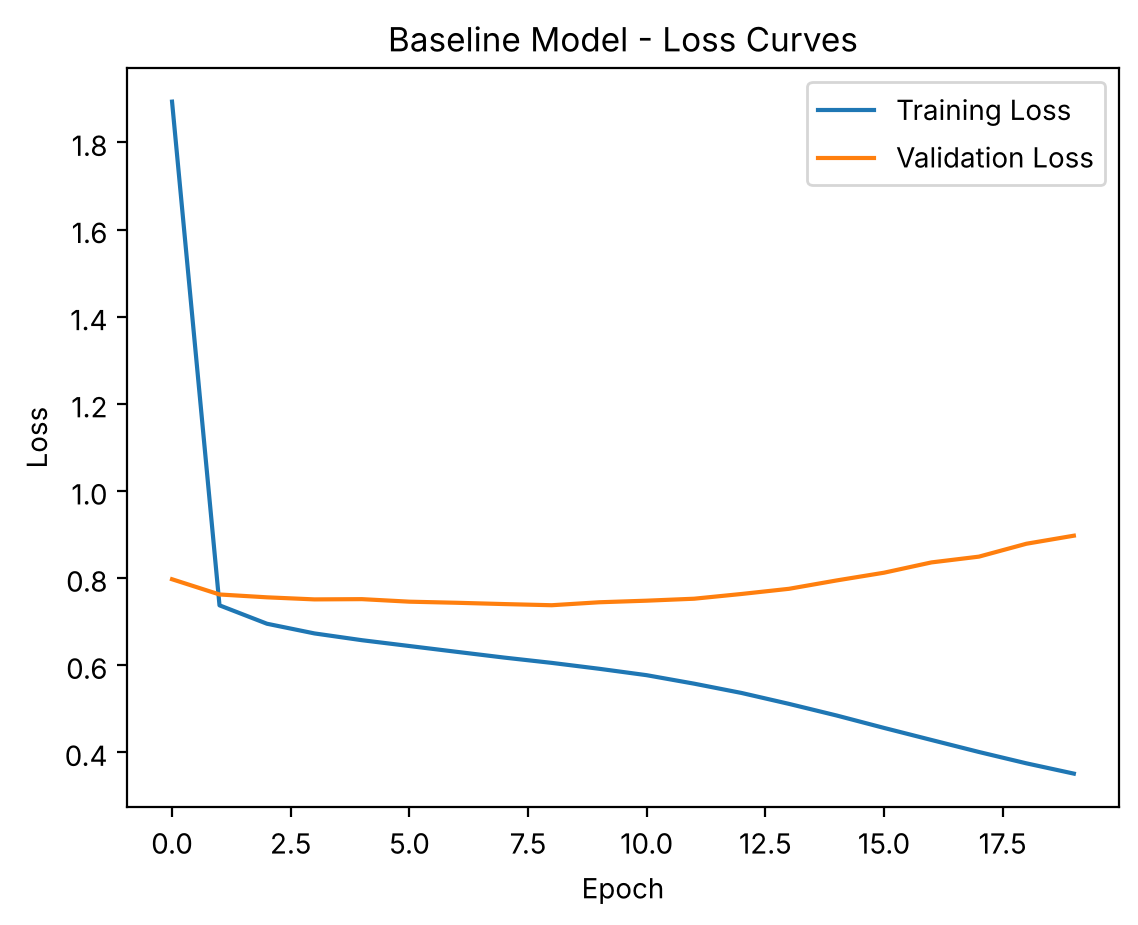

In [ ]:
plt.plot(baseline_history.history['loss'], label='Training Loss')
plt.plot(baseline_history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Baseline Model - Loss Curves')
plt.legend()
plt.show()



* Training Loss: The model learned from the training data, and the error decreased over time

* Validation Loss: The performance on the validation data has generally improved, but it is not entirely stable.



### MAE Curve

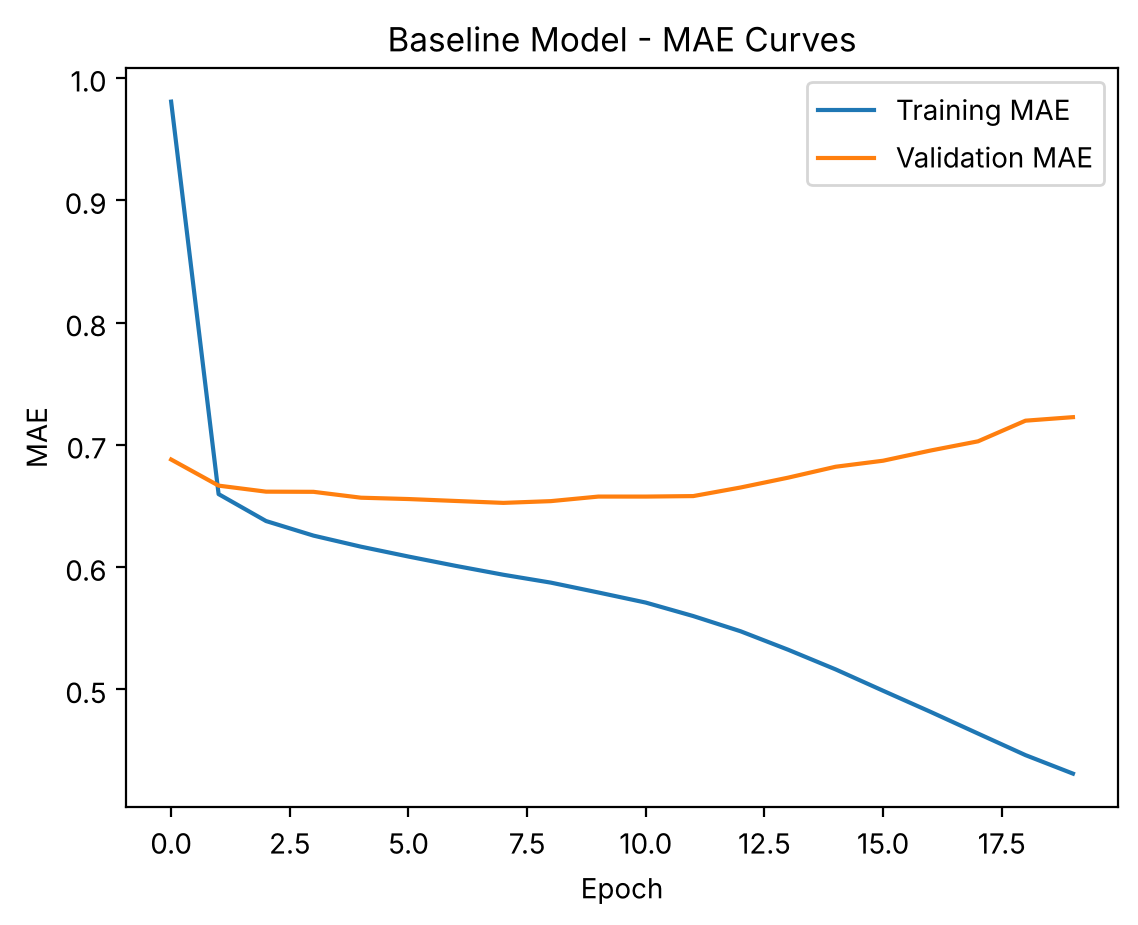

In [ ]:
plt.plot(baseline_history.history['mae'], label='Training MAE')
plt.plot(baseline_history.history['val_mae'], label='Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.title('Baseline Model - MAE Curves')
plt.legend()
plt.show()

* Training MAE: The model began learning from the training data, and the average error decreased over time.

* Validation MAE: The performance on the validation data has generally improved, but the results show some fluctuation.

### Baseline Training Results

In [ ]:
print('Training Loss:', min(baseline_history.history['loss']))
print('Validation Loss:', min(baseline_history.history['val_loss']))
print('Training MAE:', min(baseline_history.history['mae']))
print('Validation MAE:', min(baseline_history.history['val_mae']))

Training Loss: 0.3513478636741638
Validation Loss: 0.7378231287002563
Training MAE: 0.431212455034256
Validation MAE: 0.6525893211364746


# Hyperparameter Tuning

### Model Function

We use the same layers as the baseline model.

In [ ]:
def build_model(lr, l2_value=0.0):
    keras.utils.set_random_seed(42)
    model = keras.Sequential([
        keras.Input(shape=(2,)),
        keras.layers.Embedding(n_users + n_movies, 32),
        keras.layers.Flatten(),
        keras.layers.Dense(128, activation='relu',
                           kernel_regularizer=keras.regularizers.l2(float(l2_value))),
        keras.layers.Dense(64, activation='relu',
                           kernel_regularizer=keras.regularizers.l2(float(l2_value))),
        keras.layers.Dense(32, activation='relu',
                           kernel_regularizer=keras.regularizers.l2(float(l2_value))),
        keras.layers.Dense(1, activation='linear')
    ])

    model.compile(optimizer=keras.optimizers.Adam(learning_rate=float(lr)),
                  loss='mse', metrics=['mae'])
    return model

Change number of Layers:

In [ ]:
layers_model = keras.Sequential([
    keras.Input(shape=(2,)),
    keras.layers.Embedding(n_users + n_movies, 32),  # learns a vector for each user and each movie
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(1, activation='linear')
])
layers_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                       loss='mse', metrics=['mae'])

layers_history = layers_model.fit(X_train, y_train,
                                      validation_data=(X_val, y_val),
                                      epochs=20, batch_size=256, verbose=1)

val_mse, val_mae = layers_model.evaluate(X_val, y_val, verbose=0)

print(f'Validation MSE: {val_mse:.4f}')
print(f'Validation MAE: {val_mae:.4f}')

Epoch 1/20


  1/316 ━━━━━━━━━━━━━━━━━━━━ 4:28 852ms/step - loss: 14.2868 - mae: 3.6385

 16/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 12.0336 - mae: 3.3030    

 33/316 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 9.4192 - mae: 2.8306 

 51/316 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 6.6969 - mae: 2.1986

 67/316 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.3544 - mae: 1.8714

... (434 outputs left out)

285/316 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1511 - mae: 0.2889

302/316 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1519 - mae: 0.2896

316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1526 - mae: 0.2904 - val_loss: 1.0181 - val_mae: 0.7645


Validation MSE: 1.0181
Validation MAE: 0.7645


- Add dropout (0.5)

In [ ]:
dropout_model = keras.Sequential([
    keras.Input(shape=(2,)),
    keras.layers.Embedding(n_users + n_movies, 32),  # learns a vector for each user and each movie
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(1, activation='linear')  #
])

dropout_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                      loss='mse', metrics=['mae'])

dropout_history = dropout_model.fit(X_train, y_train,
                                    validation_data=(X_val, y_val),
                                    epochs=20, batch_size=256, verbose=1)

val_mse, val_mae = dropout_model.evaluate(X_val, y_val, verbose=0)

print(f'Validation MSE: {val_mse:.4f}')
print(f'Validation MAE: {val_mae:.4f}')

Epoch 1/20


  1/316 ━━━━━━━━━━━━━━━━━━━━ 3:32 675ms/step - loss: 14.2617 - mae: 3.6324

 12/316 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 12.6178 - mae: 3.3923    

 27/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 11.1005 - mae: 3.1484

 44/316 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 8.4530 - mae: 2.6007 

 62/316 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 6.8232 - mae: 2.2408

... (499 outputs left out)

302/316 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5091 - mae: 0.5538

314/316 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5096 - mae: 0.5542

316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.5096 - mae: 0.5542 - val_loss: 0.7719 - val_mae: 0.6722


Validation MSE: 0.7719
Validation MAE: 0.6722


### Early Stopping

We stop training if validation MAE does not improve for 5 epochs.

In [ ]:
def early_stopping():
    return keras.callbacks.EarlyStopping(monitor='val_mae',
                                         patience=5, mode='min',
                                         restore_best_weights=True)

### Learning Rate

We try 3 learning rates with batch size 32.

In [ ]:
learning_rates = [0.00001, 0.0001, 0.001]
lr_results = []

for lr in learning_rates:
    print('Learning Rate:', lr)
    model = build_model(lr)
    history = model.fit(X_train, y_train, epochs=20, batch_size=32,
                        validation_data=(X_val, y_val),
                        callbacks=[early_stopping()], verbose=2)
    lr_results.append([lr, min(history.history['val_mae'])])

lr_results = pd.DataFrame(lr_results, columns=['Learning Rate', 'Validation MAE'])
lr_results

Learning Rate: 1e-05
Epoch 1/20


2521/2521 - 8s - 3ms/step - loss: 10.0258 - mae: 2.9569 - val_loss: 4.3497 - val_mae: 1.8703


Epoch 2/20


2521/2521 - 8s - 3ms/step - loss: 1.6825 - mae: 1.0512 - val_loss: 1.0836 - val_mae: 0.8283


Epoch 3/20


2521/2521 - 10s - 4ms/step - loss: 1.0048 - mae: 0.7909 - val_loss: 0.9541 - val_mae: 0.7682


... (69 outputs left out)

2521/2521 - 9s - 3ms/step - loss: 0.4568 - mae: 0.5021 - val_loss: 0.8773 - val_mae: 0.7213


Epoch 6/20


2521/2521 - 8s - 3ms/step - loss: 0.4297 - mae: 0.4864 - val_loss: 0.8925 - val_mae: 0.7224


,Learning Rate,Validation MAE
0,0.00001,0.664714
1,0.00010,0.665203
2,0.00100,0.665268


Best Learning Rate: 1e-05


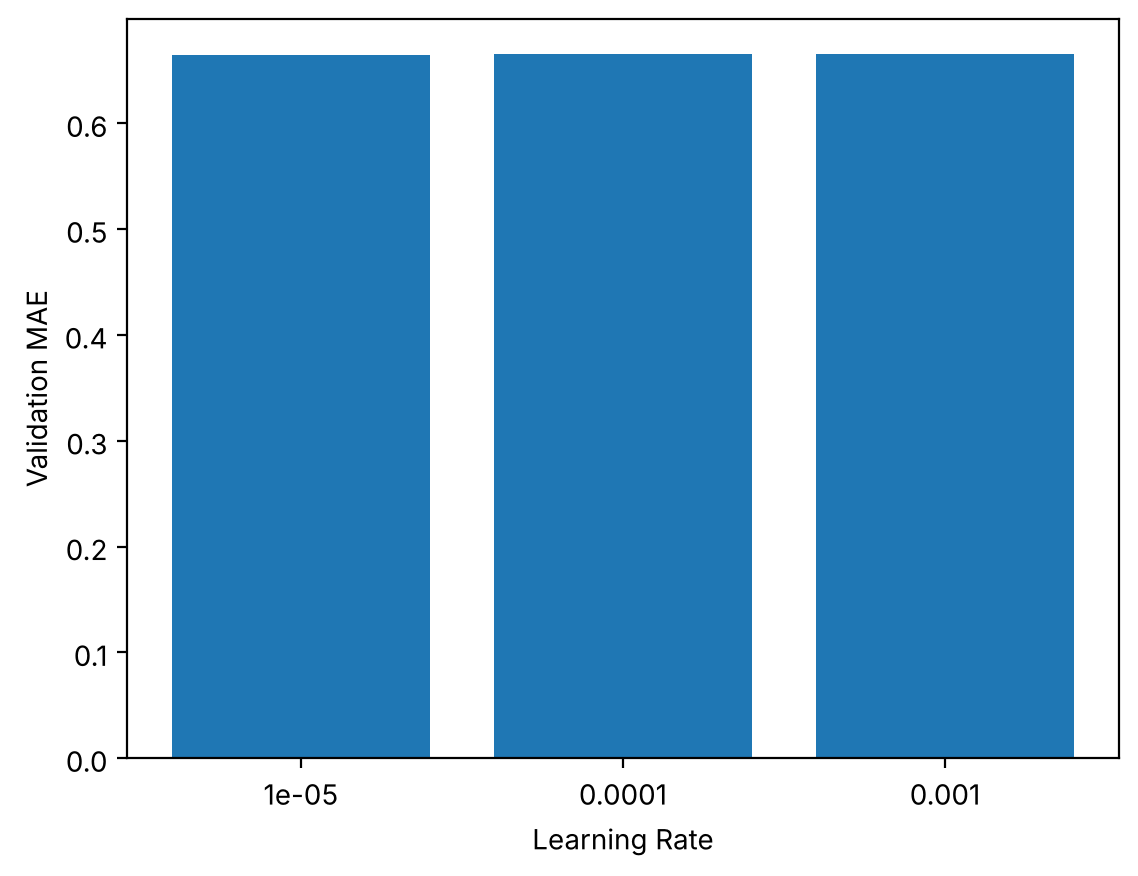

In [ ]:
best_lr = float(lr_results.loc[lr_results['Validation MAE'].idxmin(), 'Learning Rate'])
print('Best Learning Rate:', best_lr)

plt.bar(lr_results['Learning Rate'].astype(str), lr_results['Validation MAE'])
plt.xlabel('Learning Rate')
plt.ylabel('Validation MAE')
plt.show()

### Batch Size

We use the best learning rate and try 3 batch sizes.

In [ ]:
batch_sizes = [32, 64, 128]
batch_results = []

for batch in batch_sizes:
    print('Batch Size:', batch)
    model = build_model(best_lr)
    history = model.fit(X_train, y_train, epochs=20, batch_size=batch,
                        validation_data=(X_val, y_val),
                        callbacks=[early_stopping()], verbose=2)
    batch_results.append([batch, min(history.history['val_mae'])])

batch_results = pd.DataFrame(batch_results, columns=['Batch Size', 'Validation MAE'])
batch_results

Batch Size: 32
Epoch 1/20


2521/2521 - 9s - 4ms/step - loss: 10.0258 - mae: 2.9569 - val_loss: 4.3497 - val_mae: 1.8703


Epoch 2/20


2521/2521 - 10s - 4ms/step - loss: 1.6825 - mae: 1.0512 - val_loss: 1.0836 - val_mae: 0.8283


Epoch 3/20


2521/2521 - 9s - 4ms/step - loss: 1.0048 - mae: 0.7909 - val_loss: 0.9541 - val_mae: 0.7682


... (111 outputs left out)

631/631 - 2s - 4ms/step - loss: 0.7259 - mae: 0.6559 - val_loss: 0.7893 - val_mae: 0.6820


Epoch 20/20


631/631 - 2s - 3ms/step - loss: 0.7176 - mae: 0.6514 - val_loss: 0.7847 - val_mae: 0.6793


,Batch Size,Validation MAE
0,32,0.664714
1,64,0.667633
2,128,0.679281


Best Batch Size: 32


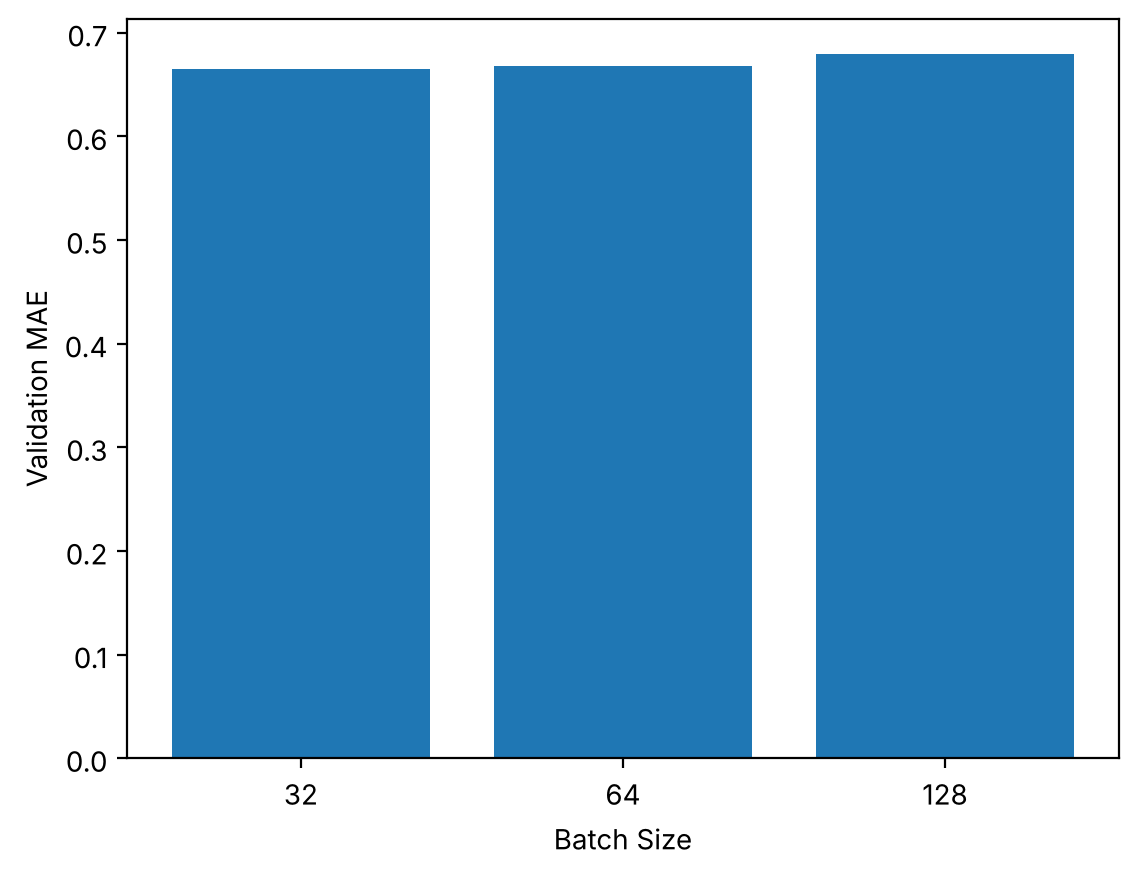

In [ ]:
best_batch = int(batch_results.loc[batch_results['Validation MAE'].idxmin(), 'Batch Size'])
print('Best Batch Size:', best_batch)

plt.bar(batch_results['Batch Size'].astype(str), batch_results['Validation MAE'])
plt.xlabel('Batch Size')
plt.ylabel('Validation MAE')
plt.show()

### L2 Regularization

We try different L2 values to reduce overfitting.

In [ ]:
l2_values = [0.0, 0.0001, 0.001]
l2_results = []
l2_models = []
l2_histories = []

for l2_value in l2_values:
    print('L2:', l2_value)
    model = build_model(best_lr, l2_value)
    history = model.fit(X_train, y_train, epochs=20, batch_size=best_batch,
                        validation_data=(X_val, y_val),
                        callbacks=[early_stopping()], verbose=2)
    l2_results.append([l2_value, min(history.history['val_mae'])])
    l2_models.append(model)
    l2_histories.append(history)

l2_results = pd.DataFrame(l2_results, columns=['L2 Value', 'Validation MAE'])
l2_results

L2: 0.0
Epoch 1/20


2521/2521 - 10s - 4ms/step - loss: 10.0258 - mae: 2.9569 - val_loss: 4.3497 - val_mae: 1.8703


Epoch 2/20


2521/2521 - 8s - 3ms/step - loss: 1.6825 - mae: 1.0512 - val_loss: 1.0836 - val_mae: 0.8283


Epoch 3/20


2521/2521 - 8s - 3ms/step - loss: 1.0048 - mae: 0.7909 - val_loss: 0.9541 - val_mae: 0.7682


... (111 outputs left out)

2521/2521 - 8s - 3ms/step - loss: 0.7755 - mae: 0.6193 - val_loss: 0.8702 - val_mae: 0.6643


Epoch 20/20


2521/2521 - 10s - 4ms/step - loss: 0.7697 - mae: 0.6172 - val_loss: 0.8674 - val_mae: 0.6639


,L2 Value,Validation MAE
0,0.0000,0.664714
1,0.0001,0.664647
2,0.0010,0.663914


Best L2: 0.001


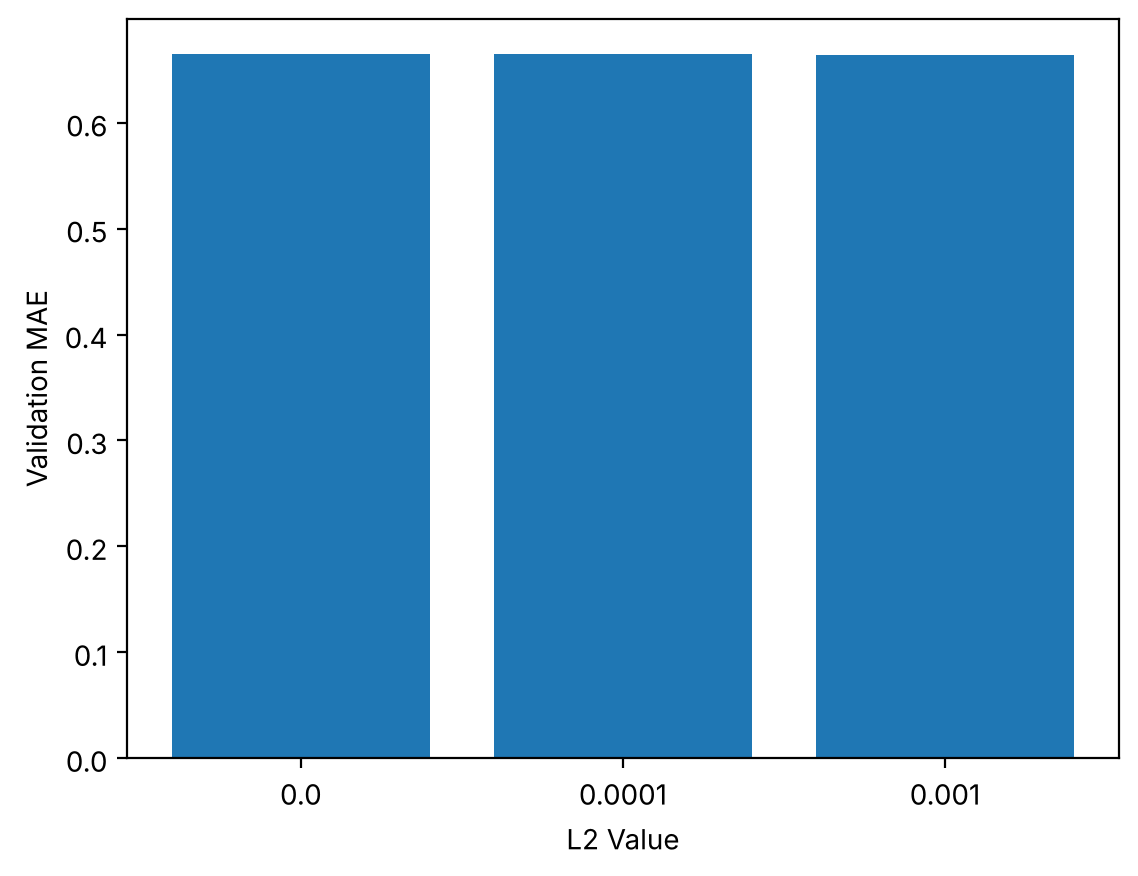

In [ ]:
best_index = int(l2_results['Validation MAE'].idxmin())
best_l2 = float(l2_results.loc[best_index, 'L2 Value'])
print('Best L2:', best_l2)

plt.bar(l2_results['L2 Value'].astype(str), l2_results['Validation MAE'])
plt.xlabel('L2 Value')
plt.ylabel('Validation MAE')
plt.show()

### Final Optimized Model

We select the model with the lowest validation MAE.

In [ ]:
Final_Model = l2_models[best_index]
final_history = l2_histories[best_index]

print('Learning Rate:', best_lr)
print('Batch Size:', best_batch)
print('L2:', best_l2)
print('Validation MAE:', min(final_history.history['val_mae']))
Final_Model.summary()

Learning Rate: 1e-05
Batch Size: 32
L2: 0.001
Validation MAE: 0.6639140248298645


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_11 (Embedding)        │ (None, 2, 32)          │       330,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_11 (Flatten)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,048,133 (4.00 MB)

 Trainable params: 349,377 (1.33 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 698,756 (2.67 MB)

### Final Model - Loss Curve

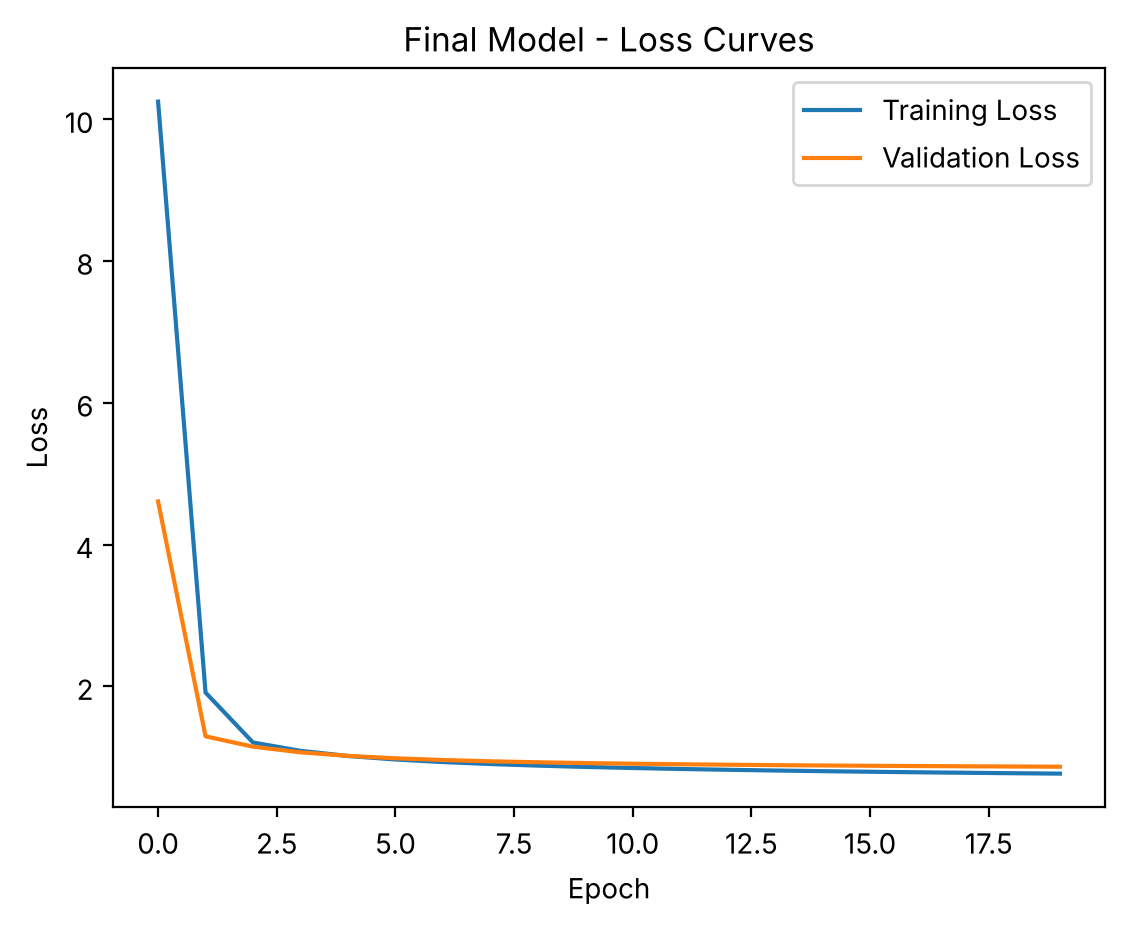

In [ ]:
plt.plot(final_history.history['loss'], label='Training Loss')
plt.plot(final_history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Final Model - Loss Curves')
plt.legend()
plt.show()

### Final Model - MAE Curve

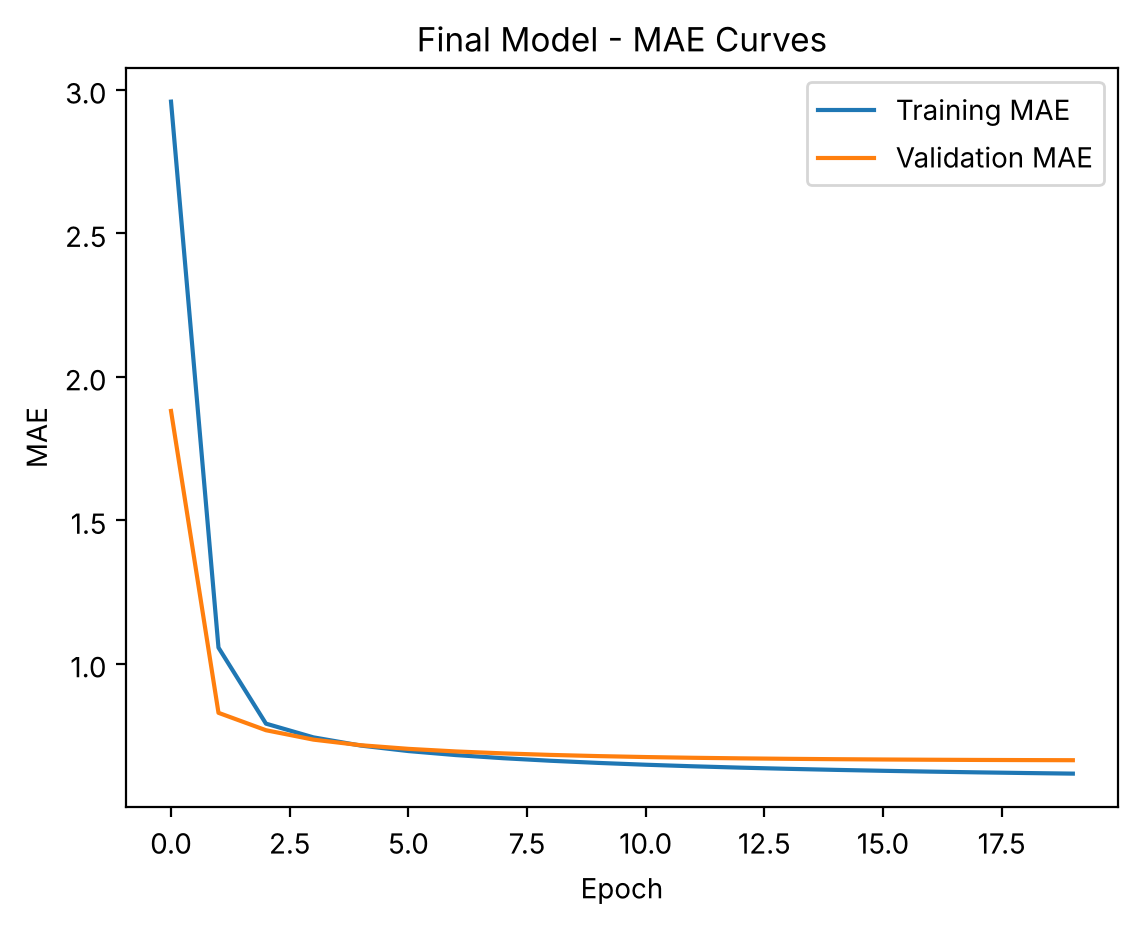

In [ ]:
plt.plot(final_history.history['mae'], label='Training MAE')
plt.plot(final_history.history['val_mae'], label='Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.title('Final Model - MAE Curves')
plt.legend()
plt.show()

### Final Evaluation

**Metrics:**
* **MAE**: average difference between the real and predicted rating.
* **RMSE**: similar to MAE but gives more penalty to big mistakes.
* We also compare with a simple mean rating predictor (always predicts the average rating) to check that our models actually learned something.

In [ ]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error

def evaluate(y_pred, name):
    # ratings are between 0.5 and 5
    y_pred = np.clip(y_pred, 0.5, 5.0)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    return [name, mae, rmse]

mean_pred = np.full(len(y_test), y_train.mean())
baseline_pred = Baseline_Model.predict(X_test, verbose=0).flatten()
final_pred = Final_Model.predict(X_test, verbose=0).flatten()

results = pd.DataFrame([
    evaluate(mean_pred, 'Mean Rating'),
    evaluate(baseline_pred, 'Baseline Model'),
    evaluate(final_pred, 'Final Model')
], columns=['Model', 'Test MAE', 'Test RMSE'])

results

,Model,Test MAE,Test RMSE
0,Mean Rating,0.830602,1.050183
1,Baseline Model,0.719577,0.949166
2,Final Model,0.674307,0.883368


### Test Results Comparison

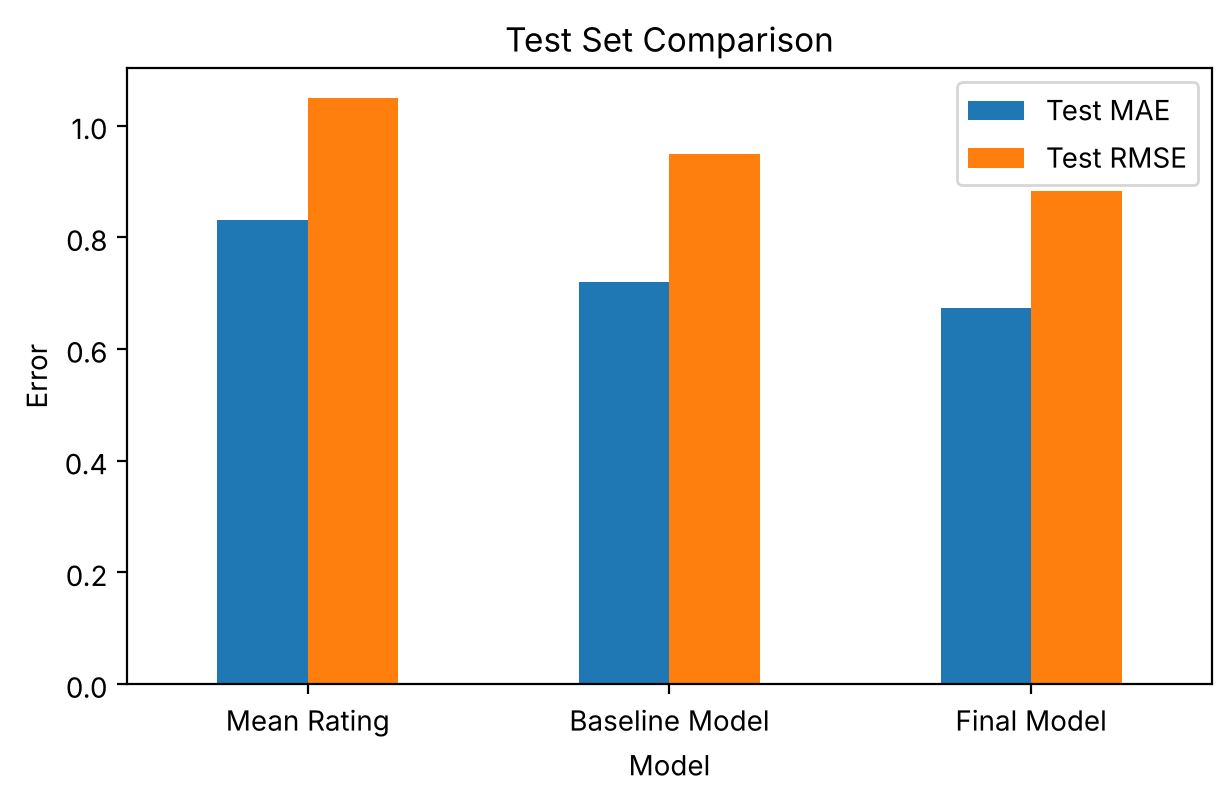

Best model on test set: Final Model


In [ ]:
results.set_index('Model').plot(kind='bar', figsize=(7, 4))
plt.ylabel('Error')
plt.title('Test Set Comparison')
plt.xticks(rotation=0)
plt.show()

best = results.loc[results['Test MAE'].idxmin(), 'Model']
print('Best model on test set:', best)

### Sample Predictions

Actual vs predicted ratings for some test examples using the final model.

In [ ]:
sample = test_df[['userId', 'movieId', 'rating']].copy()
sample['predicted'] = np.clip(final_pred, 0.5, 5.0).round(2)
sample = sample.merge(movies[['movieId', 'title']], on='movieId', how='left')
sample[['userId', 'title', 'rating', 'predicted']].head(10)

,userId,title,rating,predicted
0,491,Meet the Fockers (2004),4.0,3.70
1,603,Apocalypse Now (1979),5.0,4.17
2,412,Alien (1979),4.0,4.09
3,292,Toy Story 3 (2010),4.0,4.17
4,1,"Lord of the Rings, The (1978)",5.0,3.68
5,290,Alive (1993),3.0,3.88
6,42,For Your Eyes Only (1981),5.0,3.74
7,580,"Lock, Stock & Two Smoking Barrels (1998)",4.5,3.88
8,593,"Incredibles, The (2004)",3.0,3.49
9,233,The Shape of Water (2017),3.5,3.00


## Evaluation Summary
- The model with the lowest Test MAE and Test RMSE is the best model.
- Both neural network models have lower errors than the Mean Rating predictor, which means they learned useful patterns from users and movies.

## Limitations
1. About 100K ratings from only 610 users.Many movies have very few ratings,so their embeddings are weak.
2. The model cannot predict ratings for new users.
3. The dataset contains mostly older movies.

## Future Work
1. Use larger and more recent MovieLens datasets, such as the 25M ratings set.
2. Allow new users to rate a few movies, then use their ratings to learn their preferences and predict ratings for other movies.